# Time Series - Günlük Suç Sayısı Tahmini

Bu projede Los Angeles'ta günlük bildirilen suç sayısını tahmin edeceğiz.

In [1]:
import pandas as pd
import numpy as np
pd.set_option('display.max_columns',100)

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('la_crime.csv',usecols=['DATE OCC'])
df['tarih']=pd.to_datetime(df['DATE OCC'],format='mixed',errors='coerce').dt.normalize()

In [3]:
df.head()

,DATE OCC,tarih
0,2020 Nov 07 12:00:00 AM,2020-11-07
1,2020 Oct 18 12:00:00 AM,2020-10-18
2,2020 Oct 30 12:00:00 AM,2020-10-30
3,2020 Dec 24 12:00:00 AM,2020-12-24
4,2020 Sep 29 12:00:00 AM,2020-09-29


In [4]:
df['tarih'].isnull().sum()

np.int64(0)

### Günlük suç sayısı

In [23]:
gunluk=df.groupby('tarih').size()
gunluk=gunluk.asfreq('D',fill_value=0) 
gunluk=gunluk.iloc[:-7]                  

In [6]:
gunluk.head()

tarih
2020-01-01    1164
2020-01-02     528
2020-01-03     596
2020-01-04     541
2020-01-05     506
Freq: D, dtype: int64

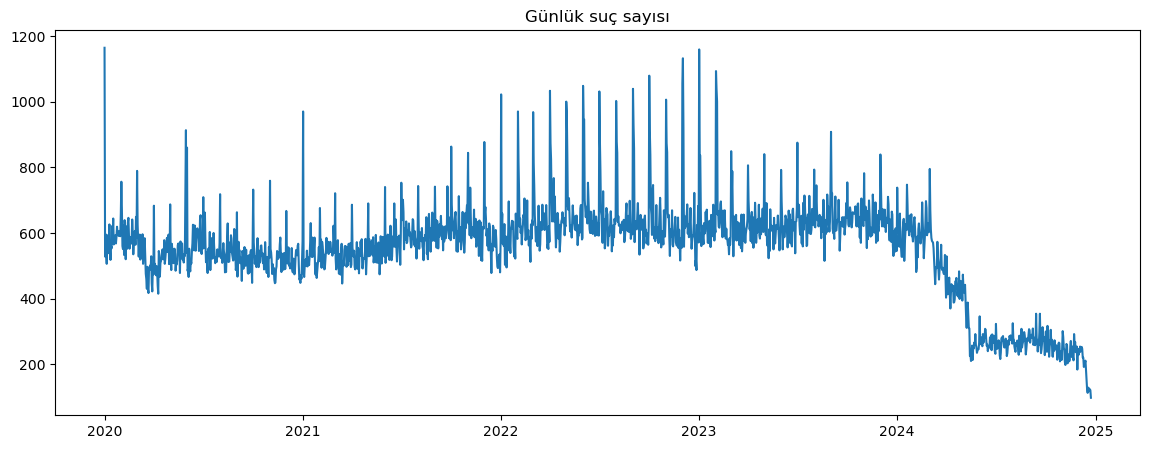

In [7]:
plt.figure(figsize=(14,5))
plt.plot(gunluk)
plt.title('Günlük suç sayısı')
plt.show()

In [8]:
gunluk.groupby(gunluk.index.dayofweek).mean()   # 0=Pazartesi

tarih
0    544.323077
1    532.980695
2    548.607692
3    545.034615
4    590.703846
5    566.780769
6    536.838462
dtype: float64

In [9]:
ts=pd.DataFrame({'suc':gunluk})
ts['lag1']=ts['suc'].shift(1)
ts['lag7']=ts['suc'].shift(7)
ts['lag14']=ts['suc'].shift(14)
ts['ort7']=ts['suc'].shift(1).rolling(7).mean()
ts['haftanin_gunu']=ts.index.dayofweek
ts['ay']=ts.index.month
ts=ts.dropna()

In [10]:
ts.head()

,suc,lag1,lag7,lag14,ort7,haftanin_gunu,ay
tarih,,,,,,,
2020-01-15,621,553.0,539.0,1164.0,559.857143,2,1
2020-01-16,592,621.0,576.0,528.0,571.571429,3,1
2020-01-17,644,592.0,626.0,596.0,573.857143,4,1
2020-01-18,565,644.0,547.0,541.0,576.428571,5,1
2020-01-19,575,565.0,518.0,506.0,579.000000,6,1


In [11]:
test_sayisi=60
train=ts.iloc[:-test_sayisi]
test=ts.iloc[-test_sayisi:]

In [12]:
x_train=train.drop('suc',axis=1)
y_train=train['suc']
x_test=test.drop('suc',axis=1)
y_test=test['suc']

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [14]:
L=LinearRegression()
L.fit(x_train,y_train)
Ltahmin=L.predict(x_test)

In [15]:
r2_score(y_test,Ltahmin)

0.5613859093688154

In [16]:
np.sqrt(mean_squared_error(y_test,Ltahmin))  #RMSE

np.float64(31.300442069932323)

In [17]:
r=RandomForestRegressor(n_estimators=200,random_state=42)
r.fit(x_train,y_train)
rtahmin=r.predict(x_test)

In [18]:
r2_score(y_test,rtahmin)

-0.3992197817489924

In [19]:
np.sqrt(mean_squared_error(y_test,rtahmin))  #RMSE

np.float64(55.90519283423797)

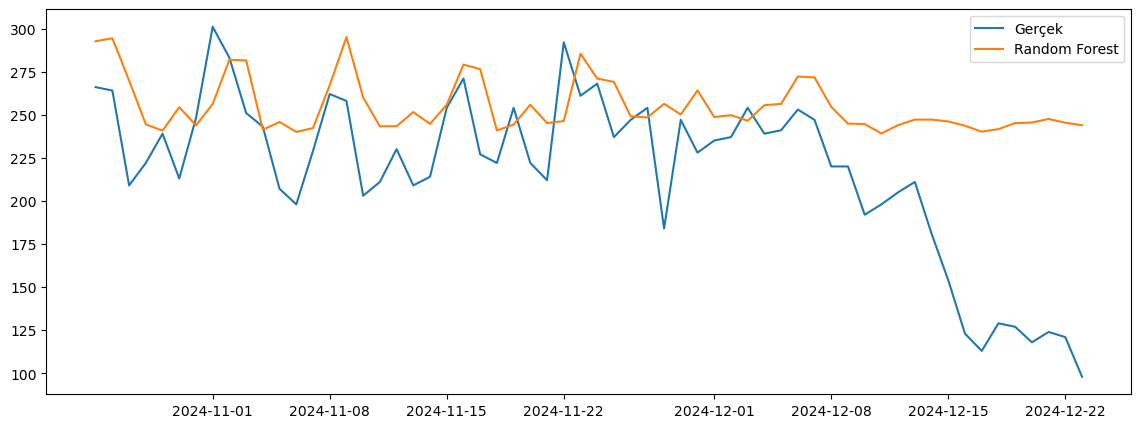

In [20]:
plt.figure(figsize=(14,5))
plt.plot(y_test.index,y_test,label='Gerçek')
plt.plot(y_test.index,rtahmin,label='Random Forest')
plt.legend()
plt.show()

In [21]:
import pickle
son_model=RandomForestRegressor(n_estimators=200,random_state=42)
son_model.fit(ts.drop('suc',axis=1),ts['suc'])
pickle.dump(son_model,open('suc_model.pkl','wb'))

In [22]:
son={'son_degerler':gunluk.iloc[-14:].tolist(),'son_tarih':gunluk.index[-1]}
pickle.dump(son,open('suc_son.pkl','wb'))